In [44]:
import io
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf
import pyarrow.parquet as pq
from sklearn.model_selection import train_test_split

from collections import Counter

In [24]:
parquet_files = sorted(
    glob.glob(
        "../data/raw/librispeech-segment/train.clean.100-*.parquet"
    )
)

print("Number of Parquet files:", len(parquet_files))

for path in parquet_files[:5]:
    print(path)

Number of Parquet files: 15
../data/raw/librispeech-segment\train.clean.100-00000-of-00015.parquet
../data/raw/librispeech-segment\train.clean.100-00001-of-00015.parquet
../data/raw/librispeech-segment\train.clean.100-00002-of-00015.parquet
../data/raw/librispeech-segment\train.clean.100-00003-of-00015.parquet
../data/raw/librispeech-segment\train.clean.100-00004-of-00015.parquet


In [25]:
table = pq.read_table(parquet_files[0])

print(table.schema)

utt_id: string
audio: struct<bytes: binary, path: string>
  child 0, bytes: binary
  child 1, path: string
text: string
phones: list<element: string>
  child 0, element: string
phone_starts: list<element: double>
  child 0, element: double
phone_ends: list<element: double>
  child 0, element: double
language: string
speaker_id: string
duration: double
split: string
-- schema metadata --
huggingface: '{"info": {"features": {"utt_id": {"dtype": "string", "_type' + 579


In [26]:
df = table.to_pandas()

print(df.shape)
print(df.columns.tolist())

(2000, 10)
['utt_id', 'audio', 'text', 'phones', 'phone_starts', 'phone_ends', 'language', 'speaker_id', 'duration', 'split']


In [27]:
audio_entry = df.iloc[0]["audio"]

print(type(audio_entry))
print(audio_entry)

<class 'dict'>
{'bytes': b'fLaC\x00\x00\x00"\x10\x00\x10\x00\x00\t\x00\x00\x183\x03\xe8\x00\xf0\x00\x00\xab\xe0,\xdf\xb1;\x1c\x06$$<o\xbd\x10>\xe1: \x03\x00\x00\x12\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x10\x00\x04\x00\x00( \x00\x00\x00reference libFLAC 1.2.1 20070917\x00\x00\x00\x00\x81\x00 \x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\

In [28]:
def load_audio(audio_entry):
    audio_bytes = audio_entry["bytes"]

    audio, sample_rate = sf.read(
        io.BytesIO(audio_bytes),
        dtype="float32"
    )

    if audio.ndim > 1:
        audio = np.mean(audio, axis=1)

    return audio, sample_rate

In [29]:
audio, sample_rate = load_audio(audio_entry)

print("Sample rate:", sample_rate)
print("Samples:", len(audio))
print("Duration:", len(audio) / sample_rate)
print("Shape:", audio.shape)

Sample rate: 16000
Samples: 44000
Duration: 2.75
Shape: (44000,)


In [30]:
phone_counts = Counter()

for path in parquet_files:
    table = pq.read_table(
        path,
        columns=["phones"]
    )

    df_phones = table.to_pandas()

    for phone_list in df_phones["phones"]:
        phone_counts.update(phone_list)

phones = sorted(phone_counts.keys())

print("Number of classes:", len(phones))
print(phones)

Number of classes: 41
['AA', 'AE', 'AH', 'AO', 'AW', 'AY', 'B', 'CH', 'D', 'DH', 'EH', 'ER', 'EY', 'F', 'G', 'HH', 'IH', 'IY', 'JH', 'K', 'L', 'M', 'N', 'NG', 'OW', 'OY', 'P', 'R', 'S', 'SH', 'T', 'TH', 'UH', 'UW', 'V', 'W', 'Y', 'Z', 'ZH', '[SIL]', '[UNK]']


In [31]:
phone_to_id = {
    phone: i
    for i, phone in enumerate(phones)
}

id_to_phone = {
    i: phone
    for phone, i in phone_to_id.items()
}

print(phone_to_id)

{'AA': 0, 'AE': 1, 'AH': 2, 'AO': 3, 'AW': 4, 'AY': 5, 'B': 6, 'CH': 7, 'D': 8, 'DH': 9, 'EH': 10, 'ER': 11, 'EY': 12, 'F': 13, 'G': 14, 'HH': 15, 'IH': 16, 'IY': 17, 'JH': 18, 'K': 19, 'L': 20, 'M': 21, 'N': 22, 'NG': 23, 'OW': 24, 'OY': 25, 'P': 26, 'R': 27, 'S': 28, 'SH': 29, 'T': 30, 'TH': 31, 'UH': 32, 'UW': 33, 'V': 34, 'W': 35, 'Y': 36, 'Z': 37, 'ZH': 38, '[SIL]': 39, '[UNK]': 40}


In [32]:
# PARAMETERS
SAMPLE_RATE = 16000

FRAME_LENGTH = 0.025   # 25 ms
FRAME_HOP = 0.020      # 20 ms

N_FFT = 400
HOP_LENGTH = 320

N_MELS = 80

In [33]:
# LOG MEL
def extract_log_mel(audio, sample_rate):
    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=sample_rate,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        power=2.0,
        center=False,
    )

    log_mel = librosa.power_to_db(
        mel,
        ref=np.max
    )

    return log_mel

In [34]:
# FRAME LABELS

def create_frame_labels(
    phones,
    starts,
    ends,
    num_frames
):
    labels = []

    for frame_index in range(num_frames):

        frame_start = frame_index * FRAME_HOP
        frame_end = frame_start + FRAME_LENGTH

        best_phone = "[UNK]"
        best_overlap = 0.0

        for phone, phone_start, phone_end in zip(
            phones,
            starts,
            ends
        ):
            overlap_start = max(
                frame_start,
                phone_start
            )

            overlap_end = min(
                frame_end,
                phone_end
            )

            overlap = max(
                0.0,
                overlap_end - overlap_start
            )

            if overlap > best_overlap:
                best_overlap = overlap
                best_phone = phone

        labels.append(best_phone)

    return labels

In [35]:
# ONE EXAMPLE

example = df.iloc[0]

text = example["text"]
phones_example = example["phones"]
starts_example = example["phone_starts"]
ends_example = example["phone_ends"]

print("Text:")
print(text)

print("\nPhones:")
print(phones_example)

Text:
THERE WERE NO FAIRIES AND HOBGOBLINS ABOUT

Phones:
['[SIL]' 'DH' 'EH' 'R' 'W' 'ER' 'N' 'OW' 'F' 'EH' 'R' 'IY' 'Z' 'AH' 'N'
 'D' 'HH' 'AA' 'B' 'G' 'AA' 'B' 'L' 'IH' 'N' 'Z' 'AH' 'B' 'AW' 'T' '[SIL]'
 '[SIL]']


In [36]:
X = extract_log_mel(
    audio,
    sample_rate
)

print("Feature shape:", X.shape)
print("Number of frames:", X.shape[1])

Feature shape: (80, 137)
Number of frames: 137


In [37]:
labels = create_frame_labels(
    phones_example,
    starts_example,
    ends_example,
    X.shape[1]
)

label_ids = np.array(
    [
        phone_to_id[phone]
        for phone in labels
    ],
    dtype=np.int64
)

print("Feature frames:", X.shape[1])
print("Labels:", len(label_ids))

print("Frames match:", X.shape[1] == len(label_ids))

Feature frames: 137
Labels: 137
Frames match: True


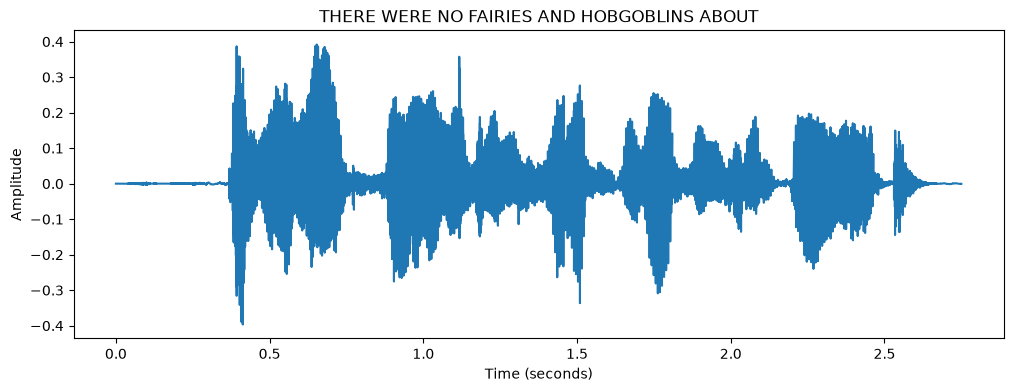

In [38]:
time = np.arange(len(audio)) / sample_rate

plt.figure(figsize=(12, 4))

plt.plot(time, audio)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title(text)

plt.show()

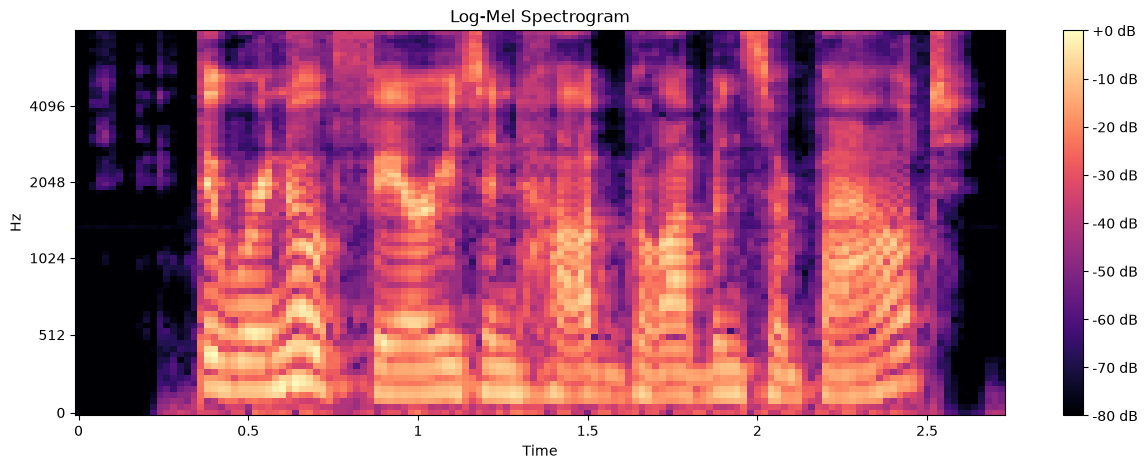

In [39]:
plt.figure(figsize=(15, 5))

librosa.display.specshow(
    X,
    sr=SAMPLE_RATE,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")
plt.title("Log-Mel Spectrogram")

plt.show()

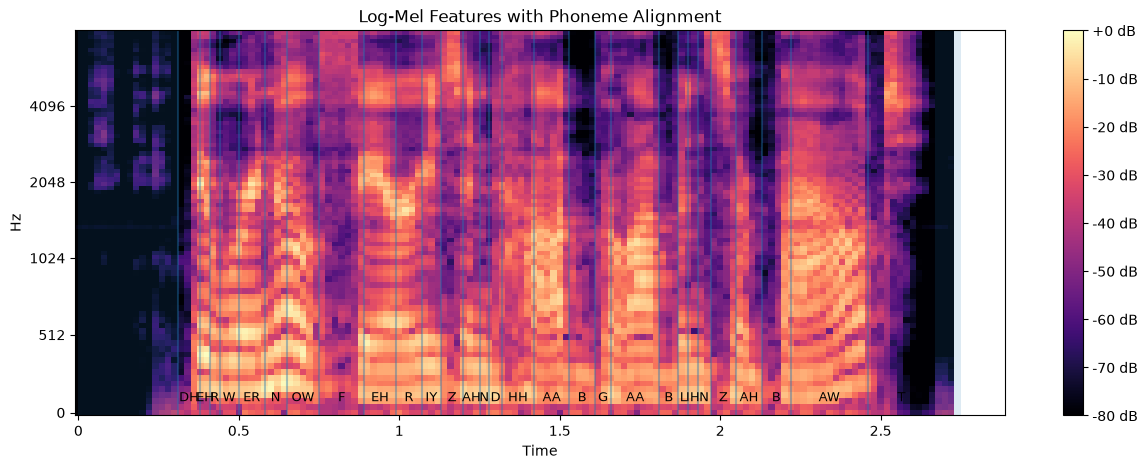

In [40]:
plt.figure(figsize=(15, 5))

librosa.display.specshow(
    X,
    sr=SAMPLE_RATE,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel"
)

for phone, start, end in zip(
    phones_example,
    starts_example,
    ends_example
):
    if phone == "[SIL]":
        plt.axvspan(
            start,
            end,
            alpha=0.15
        )
    else:
        plt.axvline(
            start,
            alpha=0.4
        )

        plt.text(
            (start + end) / 2,
            75,
            phone,
            ha="center",
            fontsize=9
        )

plt.colorbar(format="%+2.0f dB")
plt.title("Log-Mel Features with Phoneme Alignment")

plt.show()

In [41]:
decoded_labels = [
    id_to_phone[int(label)]
    for label in label_ids
]

for i in range(min(50, len(decoded_labels))):

    frame_start = i * FRAME_HOP
    frame_end = frame_start + FRAME_LENGTH

    print(
        f"{frame_start:6.3f}s - "
        f"{frame_end:6.3f}s -> "
        f"{decoded_labels[i]}"
    )

 0.000s -  0.025s -> [SIL]
 0.020s -  0.045s -> [SIL]
 0.040s -  0.065s -> [SIL]
 0.060s -  0.085s -> [SIL]
 0.080s -  0.105s -> [SIL]
 0.100s -  0.125s -> [SIL]
 0.120s -  0.145s -> [SIL]
 0.140s -  0.165s -> [SIL]
 0.160s -  0.185s -> [SIL]
 0.180s -  0.205s -> [SIL]
 0.200s -  0.225s -> [SIL]
 0.220s -  0.245s -> [SIL]
 0.240s -  0.265s -> [SIL]
 0.260s -  0.285s -> [SIL]
 0.280s -  0.305s -> [SIL]
 0.300s -  0.325s -> DH
 0.320s -  0.345s -> DH
 0.340s -  0.365s -> DH
 0.360s -  0.385s -> DH
 0.380s -  0.405s -> EH
 0.400s -  0.425s -> R
 0.420s -  0.445s -> R
 0.440s -  0.465s -> W
 0.460s -  0.485s -> W
 0.480s -  0.505s -> W
 0.500s -  0.525s -> ER
 0.520s -  0.545s -> ER
 0.540s -  0.565s -> ER
 0.560s -  0.585s -> ER
 0.580s -  0.605s -> N
 0.600s -  0.625s -> N
 0.620s -  0.645s -> N
 0.640s -  0.665s -> OW
 0.660s -  0.685s -> OW
 0.680s -  0.705s -> OW
 0.700s -  0.725s -> OW
 0.720s -  0.745s -> OW
 0.740s -  0.765s -> F
 0.760s -  0.785s -> F
 0.780s -  0.805s -> F
 0.800

In [45]:
metadata_parts = []

for path in parquet_files:
    table = pq.read_table(
        path,
        columns=["speaker_id"]
    )
    metadata_parts.append(table.to_pandas())

metadata = pd.concat(
    metadata_parts,
    ignore_index=True
)

# Convert speaker IDs to a regular NumPy array
speakers = np.array(
    metadata["speaker_id"].unique().tolist()
)

# Split speakers: 80% training, 20% test
train_speakers, test_speakers = train_test_split(
    speakers,
    test_size=0.2,
    random_state=42
)

print("Total speakers:", len(speakers))
print("Training speakers:", len(train_speakers))
print("Test speakers:", len(test_speakers))

Total speakers: 251
Training speakers: 200
Test speakers: 51
